# Modelo original: implementación

Implementación y verificación de la capa de constancia de color invariante (CCI) del capítulo de diseño:
el código de `src/original_model.py` comentado ecuación por ecuación, la verificación numérica de la
invarianza a las ganancias de canal (sintética y sobre imágenes reales de train), la comparación con el
backbone sin la capa, la complejidad empírica y la visualización de $p$, de los pesos espaciales y del
iluminante estimado en imágenes de cada fuente. Las secciones de ablación e interpretabilidad quedan
preparadas para cuando existan las corridas definitivas.

Este notebook no entrena. Mientras `backbone` sea `null` en `configs/cci.yaml` (se fija con la regla del
capítulo de diseño al cerrar el Entregable 2), se usa **MobileNetV2 como backbone provisional** para las
demostraciones: la invarianza no depende del backbone ni del entrenamiento, porque es una propiedad de la
arquitectura.

## 1. Configuración

In [1]:
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")       # sin mensajes informativos de TensorFlow
import inspect
import logging
import time

import tensorflow as tf

tf.get_logger().setLevel(logging.ERROR)
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display

from src import data as D
from src.cost import count_flops
from src.models import REGISTRY
from src.original_model import CCI_NAME, VARIANTS, CCILayer, build_cci_model, load_cci_config
from src.report import Missing
from src.train import load_model_config

cfg = D.load_config()
with open(D.PROJECT_ROOT / "configs" / "cci.yaml", encoding="utf-8") as f:
    cci_cfg = yaml.safe_load(f)
BACKBONE = cci_cfg["backbone"] or "mobilenetv2"          # provisional mientras la regla no fije el backbone
PROVISIONAL = cci_cfg["backbone"] is None
SEED = int(cfg["seed"])
keras.mixed_precision.set_global_policy("float32")
keras.utils.set_random_seed(SEED)
print(f"Backbone: {BACKBONE}{' (provisional)' if PROVISIONAL else ''}; parámetros de la capa: {load_cci_config()}")

Backbone: mobilenetv2; parámetros de la capa: {'reduced_size': 56, 'filters': 16, 'kernel_size': 3, 'eps': 0.001, 'kappa': 170.0, 'p_init': 6.0, 'input_range': [0.0, 255.0]}


## 2. Código de la capa

La capa es una subclase de `tf.keras.layers.Layer` (`keras.layers.Layer` en Keras 3). Cada método
implementa una ecuación del capítulo de diseño:

| Paso | Ecuación | Método |
|---|---|---|
| $x \leftarrow \max(x, \varepsilon)$ y $\bar{x} = \operatorname{pool}(x)$ | — | `_forward`, `area_pool` (promedio de áreas: `AveragePooling2D` si el lado es múltiplo de 56) |
| $z_{i,c} = \log \bar{x}_{i,c} - \operatorname{media}_j \log \bar{x}_{j,c}$ | (cci-guia) | `guide` |
| $\log w = \operatorname{log\_softmax}(g_\phi(z))$, $p = 1 + \operatorname{softplus}(\vartheta)$ | (cci-pesos) | `log_weights`, `p` |
| $\log e_c = \tfrac{1}{p}\operatorname{logsumexp}_i(\log w_i + p \log \bar{x}_{i,c})$ | (cci-iluminante) | `log_illuminant` |
| $h_{i,c} = \kappa\, x_{i,c} / e_c$ | (cci-correccion) | `_forward` |

Los flags `learn_p`, `learn_weights` e `invariant` dan las variantes de ablación; `explain` devuelve $p$,
los pesos, el iluminante y la imagen corregida para visualizarlos.

In [2]:
for name in ("__init__", "build", "area_pool", "guide", "log_weights", "log_illuminant", "_forward", "call"):
    display(Markdown(f"```python\n{inspect.getsource(getattr(CCILayer, name))}```"))

```python
    def __init__(
        self,
        reduced_size: int = 56,
        filters: int = 16,
        kernel_size: int = 3,
        eps: float = 1e-3,
        kappa: float = 170.0,
        p_init: float = 6.0,
        learn_p: bool = True,
        learn_weights: bool = True,
        invariant: bool = True,
        input_range=(0.0, 255.0),
        **kwargs,
    ):
        kwargs.setdefault("dtype", "float32")
        super().__init__(**kwargs)
        if p_init < 1:
            raise ValueError(f"p_init debe ser >= 1 (p = 1 + softplus(ϑ)), no {p_init}")
        if eps <= 0 or kappa <= 0:
            raise ValueError("eps y kappa deben ser positivos")
        self.reduced_size = int(reduced_size)
        self.filters = int(filters)
        self.kernel_size = int(kernel_size)
        self.eps = float(eps)
        self.kappa = float(kappa)
        self.p_init = float(p_init)
        self.learn_p = bool(learn_p)
        self.learn_weights = bool(learn_weights)
        self.invariant = bool(invariant)
        self.input_range = (float(input_range[0]), float(input_range[1]))
        self.weight_net = None
        if self.learn_weights:
            policy = self.dtype_policy
            last = keras.layers.Conv2D(1, 1, kernel_initializer="zeros", bias_initializer="zeros",
                                       dtype=policy, name="g_out")
            self.weight_net = keras.Sequential([
                keras.layers.Conv2D(self.filters, self.kernel_size, padding="same", activation="relu",
                                    dtype=policy, name="g_conv1"),
                keras.layers.Conv2D(self.filters, self.kernel_size, padding="same", activation="relu",
                                    dtype=policy, name="g_conv2"),
                last,
            ], name="g_phi")
```

```python
    def build(self, input_shape):
        self._check_shape(input_shape)
        h, w = input_shape[1], input_shape[2]
        if h is None or w is None:
            raise ValueError("CCILayer necesita alto y ancho estáticos para el promedio de áreas")
        r = self.reduced_size
        if h < r or w < r:
            raise ValueError(f"La entrada ({h} x {w}) es menor que reduced_size = {r}")
        self._spatial = (int(h), int(w))
        # Promedio de áreas: AveragePooling2D si el lado es múltiplo de reduced_size (caso del
        # proyecto: 224 = 4 x 56); si no, el producto por las matrices de area_pool_matrix.
        self._pool = None
        if h % r == 0 and w % r == 0:
            self._pool = keras.layers.AveragePooling2D(pool_size=(h // r, w // r), dtype=self.dtype_policy,
                                                       name="area_pool")
        else:
            self._pool_h = ops.convert_to_tensor(area_pool_matrix(h, r), dtype=self.compute_dtype)
            self._pool_w = ops.convert_to_tensor(area_pool_matrix(w, r), dtype=self.compute_dtype)
        self.theta = self.add_weight(
            name=THETA_NAME, shape=(),
            initializer=keras.initializers.Constant(inverse_softplus(self.p_init - 1.0)),
            trainable=self.learn_p,
        )
        if self.weight_net is not None:
            self.weight_net.build((None, r, r, 3))
        self.built = True
```

```python
    def area_pool(self, x):
        """x̄ = pool(x): promedio de áreas a reduced_size × reduced_size (lineal y por canal)."""
        if self._pool is not None:
            return self._pool(x)
        return ops.einsum("ih,bhwc,jw->bijc", self._pool_h, x, self._pool_w)
```

```python
    def guide(self, log_xbar):
        """Representación de entrada de g_φ: z (cci-guia) si `invariant`; si no, la imagen reducida
        sin normalizar en [0, 1], x̄ / max(input_range)."""
        if not self.invariant:
            return ops.exp(log_xbar) / self.input_range[1]
        return log_xbar - ops.mean(log_xbar, axis=(1, 2), keepdims=True)
```

```python
    def log_weights(self, log_xbar):
        """log w (B, N̄): log_softmax espacial de g_φ(z), ecuación (cci-pesos); uniforme sin g_φ."""
        b = ops.shape(log_xbar)[0]
        n = self.reduced_size * self.reduced_size
        if self.weight_net is None:
            return ops.reshape(ops.zeros_like(log_xbar[..., 0]), (b, n)) - math.log(n)
        scores = ops.reshape(self.weight_net(self.guide(log_xbar)), (b, n))
        return scores - ops.logsumexp(scores, axis=1, keepdims=True)
```

```python
    @staticmethod
    def log_illuminant(log_w, log_xbar_flat, p):
        """log e_c = (1/p) logsumexp_i(log w_i + p log x̄_{i,c}), ecuación (cci-iluminante) en el
        dominio logarítmico. log_w: (B, N̄); log_xbar_flat: (B, N̄, 3); p escalar. Devuelve (B, 3)."""
        return ops.logsumexp(log_w[:, :, None] + p * log_xbar_flat, axis=1) / p
```

```python
    def _forward(self, x):
        x = ops.maximum(ops.cast(x, self.compute_dtype), self.eps)        # intensidades positivas
        log_xbar = ops.log(self.area_pool(x))                              # x̄ >= ε
        b = ops.shape(x)[0]
        log_w = self.log_weights(log_xbar)
        p = self.p
        log_e = self.log_illuminant(log_w, ops.reshape(log_xbar, (b, -1, 3)), p)
        h = self.kappa * x * ops.exp(-log_e)[:, None, None, :]             # (cci-correccion)
        return h, {"p": p, "log_weights": log_w, "log_illuminant": log_e}
```

```python
    def call(self, inputs):
        self._validate(inputs)
        return self._forward(inputs)[0]
```

`build_cci_model` antepone la capa a cualquier clasificador del REGISTRY sin modificarlo: vuelve a trazar la
cadena lineal del clasificador (preprocess → backbone → cabeza) sobre la salida de la capa, con las mismas
capas y los mismos pesos.

In [3]:
display(Markdown(f"```python\n{inspect.getsource(build_cci_model)}```"))
pd.DataFrame([{"variante": v, **flags} for v, flags in VARIANTS.items()]).set_index("variante")

```python
def build_cci_model(
    backbone,
    variant: str = "full",
    *,
    n_classes: int = 7,
    dropout: float = 0.0,
    weights="default",
    layer_cfg: dict | None = None,
    name: str | None = None,
    **layer_overrides,
) -> keras.Model:
    """Antepone la capa CCI a un clasificador del REGISTRY sin modificarlo: f = softmax ∘ b_ψ ∘ h.

    `backbone`: nombre de un modelo del REGISTRY (se construye con configs/<nombre>.yaml, sus
    pesos de ImageNet, `n_classes` y `dropout`) o un keras.Model con la estructura de
    src/models/common.py (Input -> preprocess -> backbone -> cabeza). El modelo resultante es

        Input -> CCILayer -> [mismas capas del clasificador, mismos objetos y pesos]

    es decir, se vuelve a trazar la cadena lineal del clasificador sobre la salida de la capa, con
    el backbone llamado con training=False como en el original. Las capas se comparten (no se
    copian), así que get_backbone, set_backbone_trainable, head_layers y Grad-CAM funcionan igual
    y la fase A (backbone congelado) entrena la capa y la cabeza.
    """
    from src.models.common import BACKBONE_NAME

    base = _backbone_model(backbone, n_classes, dropout, weights)
    layers = [lyr for lyr in base.layers if not isinstance(lyr, keras.layers.InputLayer)]
    _check_linear_chain(base, layers)
    shape = tuple(base.inputs[0].shape[1:])
    inputs = keras.Input(shape=shape, dtype="float32", name="image")
    x = cci_layer(variant, layer_cfg, **layer_overrides)(inputs)
    for layer in layers:
        x = layer(x, training=False) if layer.name == BACKBONE_NAME else layer(x)
    return keras.Model(inputs, x, name=name or f"cci_{base.name}")
```

,learn_p,learn_weights,invariant
variante,,,
full,True,True,True
fixed_p,False,True,True
uniform_weights,True,False,True
no_invariance,True,True,False
shades_of_gray,False,False,True


## 3. Modelo y backbone sin la capa

In [4]:
backbone_model = REGISTRY[BACKBONE](load_model_config(BACKBONE), len(D.class_names(cfg)), 0.0)  # pesos de ImageNet
model = build_cci_model(backbone_model, "full")
layer = model.get_layer(CCI_NAME)
n_layer = layer.count_params()
pd.DataFrame({
    "parámetros": [backbone_model.count_params(), model.count_params(), n_layer],
    "entrenables en la fase A (backbone congelado)": [
        sum(int(np.prod(w.shape)) for w in backbone_model.trainable_weights if not w.path.startswith("backbone")),
        sum(int(np.prod(w.shape)) for w in model.trainable_weights if not w.path.startswith("backbone")), n_layer],
}, index=[f"{BACKBONE} sin la capa", f"{BACKBONE} con la capa CCI", "capa CCI"])

,parámetros,entrenables en la fase A (backbone congelado)
mobilenetv2 sin la capa,2266951,8967
mobilenetv2 con la capa CCI,2269737,11753
capa CCI,2786,2786


La capa añade 2786 parámetros (2785 de $g_\phi$, como calcula el capítulo de diseño, más $\vartheta$), una
fracción despreciable del backbone. En la fase A, con el backbone congelado, se entrenan la capa y la cabeza.

## 4. Verificación numérica de la invarianza

### 4.1 Imágenes sintéticas

Imágenes con regiones de distinto color, sin ceros ni saturación, y ganancias $d_c$ log-uniformes en
$[0{,}5;\ 2]$. Para que la prueba no dependa de los pesos iniciales (la última capa de $g_\phi$ empieza en
cero, lo que hace los pesos uniformes), se asignan pesos aleatorios a $g_\phi$ y $p = 3$.

In [5]:
rng = np.random.default_rng(SEED)


def synthetic(n, size=224):
    yy, xx = np.mgrid[0:size, 0:size]
    out = []
    for _ in range(n):
        cy, cx, r = rng.uniform(0.3, 0.7, 2).tolist() + [rng.uniform(0.15, 0.35)]
        lesion = (((yy / size - cy) ** 2 + (xx / size - cx) ** 2) < r ** 2)[..., None]
        img = np.where(lesion, rng.uniform(25, 60, 3), rng.uniform(80, 115, 3)) + rng.normal(0, 3, (size, size, 3))
        out.append(np.clip(img, 20, 120))
    return np.asarray(out, dtype="float32")


def gains(n):
    return np.exp(rng.uniform(np.log(0.5), np.log(2.0), (n, 1, 1, 3))).astype("float32")


for w in layer.weight_net.layers[-1].weights:
    w.assign(rng.normal(0, 1.0, w.shape).astype("float32"))
layer.theta.assign(np.log(np.expm1(2.0)))                    # p = 3
x = synthetic(16)
rows = []
for trial in range(5):
    d = gains(len(x))
    rows.append({"ensayo": trial,
                 "max |f(Dx) − f(x)| con la capa": float(np.abs(model.predict(x * d, verbose=0) - model.predict(x, verbose=0)).max()),
                 "max |f(Dx) − f(x)| sin la capa": float(np.abs(backbone_model.predict(x * d, verbose=0) - backbone_model.predict(x, verbose=0)).max())})
inv_synth = pd.DataFrame(rows).set_index("ensayo")
inv_synth

,max |f(Dx) − f(x)| con la capa,max |f(Dx) − f(x)| sin la capa
ensayo,,
0,6.258488e-07,0.119498
1,5.364418e-07,0.141804
2,4.470348e-07,0.086798
3,4.917383e-07,0.129756
4,5.215406e-07,0.141523


**Interpretación.** Con la capa, la discrepancia es del orden del error de redondeo de float32 (la prueba
unitaria exige menos de $10^{-4}$), mientras que el mismo backbone sin la capa cambia sus probabilidades en
varios órdenes de magnitud más con las mismas ganancias. Es la comprobación numérica del teorema del
capítulo de diseño.

### 4.2 Imágenes reales de train

Se toman 12 imágenes de train de cada fuente, redimensionadas como en el entrenamiento, y se separan según
tengan o no píxeles nulos o saturados (algún valor igual a 0 o a 255 en algún canal). Se hacen dos mediciones:

- **(a) Ganancias sin recorte.** $d_c$ log-uniforme entre 0,5 y $\min(2,\ 255 / \max_i x_{i,c})$, de modo que
  $Dx$ no sale de $[0, 255]$. Es el supuesto del teorema: la invarianza debe ser exacta salvo por los píxeles
  nulos, donde actúa la cota $\varepsilon$.
- **(b) Ganancias con recorte.** $d_c$ log-uniforme en $[0{,}5;\ 2]$ y $Dx$ recortado a $[0, 255]$, como haría
  un sensor real. Muchas imágenes dermatoscópicas tienen canales cerca de 255, de modo que una ganancia mayor
  que 1 satura píxeles y la transformación deja de ser diagonal.

In [6]:
N_PER_SOURCE = 12
splits = D.load_splits(cfg["paths"]["splits_csv"])
meta = D.load_metadata(cfg).set_index("image_id")
train_ids = splits[splits["split"] == "train"]["image_id"]
pick = meta.loc[train_ids].reset_index().groupby("dataset").sample(n=N_PER_SOURCE, random_state=SEED)
have_images = D.image_path(cfg, pick["image_id"].iloc[0]).exists()


def max_diff(a, b):
    return np.abs(a - b).max(axis=1)


if have_images:
    imgs = D.load_resized_images(cfg, pick["image_id"])
    extreme = ((imgs <= 0) | (imgs >= 255)).reshape(len(imgs), -1).any(axis=1)
    f_x, b_x = model.predict(imgs, verbose=0), backbone_model.predict(imgs, verbose=0)
    # (a) sin recorte: el límite superior de cada canal es 255 / max(x_c)
    upper = np.minimum(2.0, 255.0 / np.maximum(imgs.max(axis=(1, 2)), 1.0))[:, None, None, :]
    log_lo = np.minimum(np.log(0.5), np.log(upper))
    d_a = np.exp(rng.uniform(log_lo, np.log(upper))).astype("float32")
    x_a = np.minimum(imgs * d_a, 255.0)                    # solo corrige el redondeo en el límite
    # (b) con recorte
    d_b = gains(len(imgs))
    x_b = np.clip(imgs * d_b, 0, 255)
    real = pick[["image_id", "dataset"]].assign(
        grupo=np.where(extreme, "con píxeles nulos o saturados", "sin píxeles nulos ni saturados"),
        a_con_capa=max_diff(model.predict(x_a, verbose=0), f_x),
        a_sin_capa=max_diff(backbone_model.predict(x_a, verbose=0), b_x),
        b_pct_recortado=100 * (imgs * d_b > 255).reshape(len(imgs), -1).mean(axis=1),
        b_con_capa=max_diff(model.predict(x_b, verbose=0), f_x),
        b_sin_capa=max_diff(backbone_model.predict(x_b, verbose=0), b_x))
    display(Markdown("**(a) Ganancias sin recorte**: max |f(Dx) − f(x)| por imagen"),
            real.groupby("grupo")[["a_con_capa", "a_sin_capa"]].agg(["count", "median", "max"]))
    display(Markdown("**(b) Ganancias con recorte**: medianas por imagen"),
            real.groupby("grupo")[["b_pct_recortado", "b_con_capa", "b_sin_capa"]].median(),
            real.groupby("dataset")[["b_pct_recortado", "b_con_capa", "b_sin_capa"]].median())
else:
    display(Missing("no hay imágenes en data/raw/images."))

**(a) Ganancias sin recorte**: max |f(Dx) − f(x)| por imagen

a_con_capa                              \
                                    count        median           max   
grupo                                                                   
con píxeles nulos o saturados           2  5.662441e-07  5.960464e-07   
sin píxeles nulos ni saturados         46  4.991889e-07  1.847744e-06   

                               a_sin_capa                      
                                    count    median       max  
grupo                                                          
con píxeles nulos o saturados           2  0.039646  0.048931  
sin píxeles nulos ni saturados         46  0.104398  0.528311

**(b) Ganancias con recorte**: medianas por imagen

,b_pct_recortado,b_con_capa,b_sin_capa
grupo,,,
con píxeles nulos o saturados,17.142326,0.054278,0.258568
sin píxeles nulos ni saturados,22.093896,0.058297,0.134355


,b_pct_recortado,b_con_capa,b_sin_capa
dataset,,,
rosendahl,16.493277,0.061843,0.119995
vidir_modern,13.729672,0.027920,0.154095
vidir_molemax,26.883703,0.076792,0.134911
vienna_dias,22.528699,0.094433,0.163474


**Interpretación.** Con ganancias que no saturan ningún píxel (a), la invarianza se cumple también en las imágenes reales: la discrepancia del modelo con la capa es del orden de $10^{-7}$ a $10^{-6}$, el redondeo de float32, frente a una mediana de 0,10 en el backbone sin la capa; los pocos píxeles nulos no la alteran de forma medible. Con ganancias de hasta 2 y recorte a 255 (b), en torno al 20 % de los píxeles se saturan, porque el canal rojo de la piel ya está cerca del máximo, y la transformación deja de ser diagonal: la capa reduce el cambio de las probabilidades aproximadamente a la mitad (mediana de 0,06 frente a 0,13), pero no lo elimina. Las cifras son de esta ejecución, con MobileNetV2 como backbone provisional y la capa sin entrenar. Por eso el capítulo de diseño presenta la invarianza como garantía exacta frente a ganancias de canal y solo como motivación frente al cambio de fuente real, y la predicción secundaria 1 exceptúa la saturación.

## 5. Comparación con el backbone sin la capa

La comparación de desempeño (exactitud balanceada global, diferencia entre vidir_molemax y el resto, TOST
de no inferioridad y robustez a ganancias) requiere las corridas definitivas de `cci` y de su backbone con
el mismo protocolo. Hasta entonces se muestra el estado de las corridas.

In [7]:
from src.benchmark import load_runs
from src.final import final_label

rs = load_runs(cfg, final_label(cfg), models=["cci", BACKBONE])
if "cci" in rs.models and BACKBONE in rs.models:
    sub = rs.metrics.query("split == 'test' and metric == 'balanced_accuracy'")
    display(sub.groupby("model")["value"].agg(["count", "mean", "std"]))
else:
    display(Missing(f"faltan corridas definitivas de cci o de {BACKBONE}: python -m src.final --model cci"))

,count,mean,std
model,,,
cci,5,0.635036,0.010904
mobilenetv2,5,0.631601,0.016024


## 6. Complejidad empírica

Parámetros, FLOPs (profiler de TensorFlow, 2 FLOPs por multiplicación-suma, como `src.cost`) y tiempo por
imagen en CPU al variar la resolución de entrada (múltiplos de 56, de modo que el promedio de áreas es un
`AveragePooling2D`). La capa trabaja siempre a 56 × 56, así que solo el promedio de áreas y la corrección
crecen con el número de píxeles.

In [8]:
RESOLUTIONS = [112, 168, 224, 336, 448]
REPEATS = 20
rows = []
for size in RESOLUTIONS:
    keras.backend.clear_session()
    inp = keras.Input((size, size, 3))
    lyr = CCILayer(**load_cci_config())
    only = keras.Model(inp, lyr(inp))
    x = np.random.default_rng(0).uniform(1, 254, (1, size, size, 3)).astype("float32")
    only.predict(x, verbose=0)
    t0 = time.perf_counter()
    for _ in range(REPEATS):
        only(x)
    rows.append({"resolución": size, "píxeles": size * size, "parámetros": lyr.count_params(),
                 "MFLOPs capa": count_flops(only, size) / 1e6,
                 "ms por imagen (CPU)": 1000 * (time.perf_counter() - t0) / REPEATS})
complexity = pd.DataFrame(rows).set_index("resolución")
full_flops = count_flops(build_cci_model(backbone_model, "full"), 224) / 1e9
complexity

I0000 00:00:1795871779.743861  305475 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
I0000 00:00:1795871779.743980  305475 single_machine.cc:376] Starting new session


I0000 00:00:1795871780.252220  305475 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
I0000 00:00:1795871780.252387  305475 single_machine.cc:376] Starting new session


I0000 00:00:1795871780.820485  305475 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
I0000 00:00:1795871780.820621  305475 single_machine.cc:376] Starting new session


I0000 00:00:1795871781.348932  305475 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
I0000 00:00:1795871781.349079  305475 single_machine.cc:376] Starting new session


I0000 00:00:1795871781.902921  305475 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
I0000 00:00:1795871781.903088  305475 single_machine.cc:376] Starting new session


I0000 00:00:1795871782.312358  305475 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
I0000 00:00:1795871782.312462  305475 single_machine.cc:376] Starting new session


,píxeles,parámetros,MFLOPs capa,ms por imagen (CPU)
resolución,,,,
112,12544,2786,17.589835,12.921845
168,28224,2786,17.777995,11.720324
224,50176,2786,18.041419,12.803202
336,112896,2786,18.794059,13.482812
448,200704,2786,19.847755,13.366718


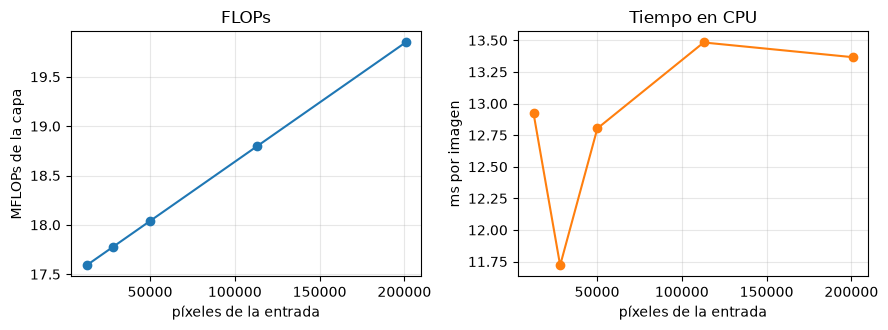

Modelo completo (mobilenetv2 con la capa) a 224 x 224: 0.63 GFLOPs; capa: 18.0 MFLOPs (2.86 % del total)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(complexity["píxeles"], complexity["MFLOPs capa"], "o-")
axes[0].set(xlabel="píxeles de la entrada", ylabel="MFLOPs de la capa", title="FLOPs")
axes[1].plot(complexity["píxeles"], complexity["ms por imagen (CPU)"], "o-", color="tab:orange")
axes[1].set(xlabel="píxeles de la entrada", ylabel="ms por imagen", title="Tiempo en CPU")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
print(f"Modelo completo ({BACKBONE} con la capa) a 224 x 224: {full_flops:.2f} GFLOPs; "
      f"capa: {complexity.loc[224, 'MFLOPs capa']:.1f} MFLOPs "
      f"({100 * complexity.loc[224, 'MFLOPs capa'] / 1000 / full_flops:.2f} % del total)")

**Interpretación.** Los FLOPs de la capa son casi constantes en la resolución: la red de pesos opera siempre
sobre 56 × 56 (unos $1{,}7 \times 10^{7}$ FLOPs, es decir, las $8{,}7 \times 10^{6}$ multiplicaciones-sumas
del capítulo de diseño) y solo el promedio de áreas y la corrección, lineales en el número de píxeles, crecen
con la entrada. El costo es despreciable frente al backbone.

## 7. Visualización de $p$, los pesos espaciales y el iluminante

Una imagen de train por fuente: la imagen de entrada, los pesos espaciales $w$ (mapa de 56 × 56), la imagen
corregida $h(x)$ y el iluminante estimado $e_c$. Si existe la corrida definitiva de `cci`
(`evaluation.gradcam.run`), se cargan sus pesos; si no, la capa está en su estado inicial (Shades of Gray con
$p = 6$ y pesos uniformes), y los pesos aleatorios de la sección 4 se descartan.

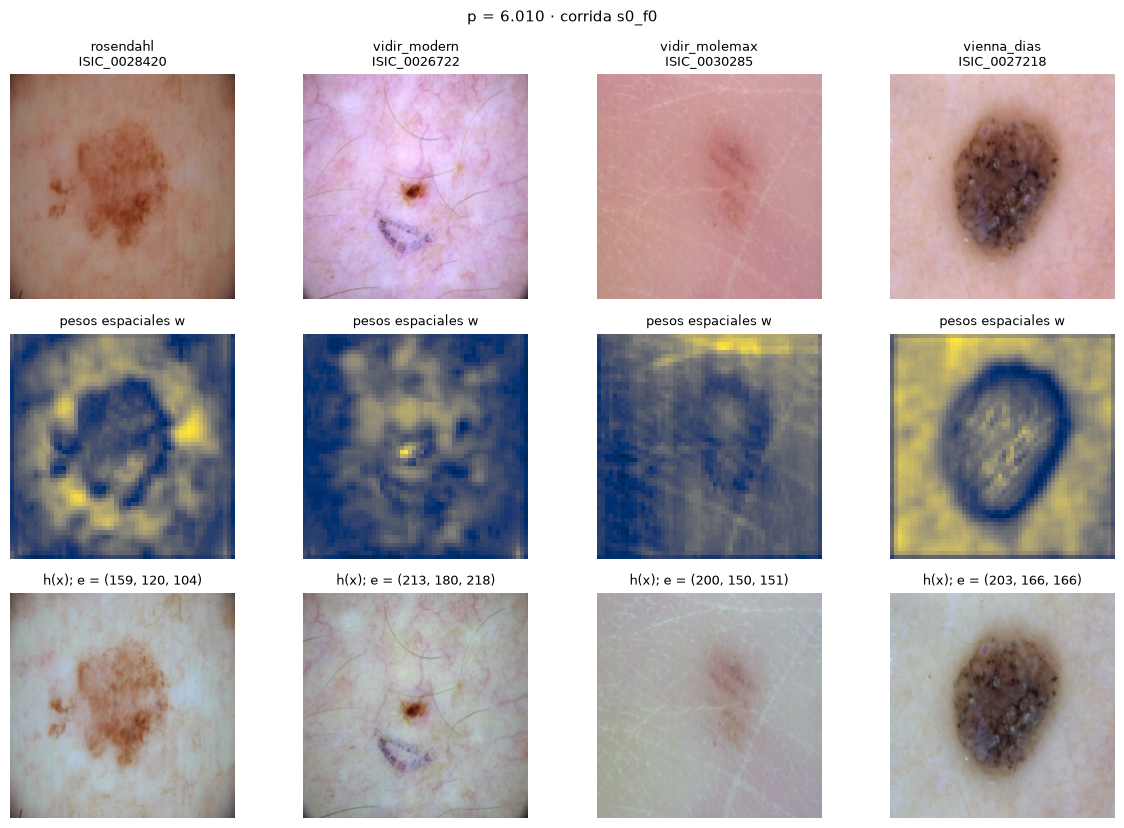

,e_R,e_G,e_B
dataset,,,
rosendahl,159.500000,120.500000,103.900002
vidir_modern,213.100006,179.699997,218.100006
vidir_molemax,200.500000,150.000000,150.500000
vienna_dias,202.699997,166.300003,166.300003


In [10]:
from src.gradcam import gradcam_run_dir, load_model_float32

run = gradcam_run_dir(cfg, "cci")
if isinstance(run, Missing):
    viz_model = build_cci_model(backbone_model, "full")
    origen = "estado inicial (sin entrenar)"
else:
    viz_model = load_model_float32(cfg, "cci", run)
    origen = f"corrida {run.name}"
viz = viz_model.get_layer(CCI_NAME)
if have_images:
    one = pick.groupby("dataset").head(1)
    info = viz.explain(D.load_resized_images(cfg, one["image_id"]))
    fig, axes = plt.subplots(3, len(one), figsize=(3 * len(one), 8.4))
    src_imgs = D.load_resized_images(cfg, one["image_id"])
    for j, (iid, source) in enumerate(zip(one["image_id"], one["dataset"])):
        axes[0, j].imshow(src_imgs[j].astype("uint8"))
        axes[0, j].set_title(f"{source}\n{iid}", fontsize=9)
        im = axes[1, j].imshow(info["weights"][j], cmap="cividis")
        axes[1, j].set_title("pesos espaciales w", fontsize=9)
        axes[2, j].imshow(np.clip(info["corrected"][j], 0, 255).astype("uint8"))
        e = info["illuminant"][j]
        axes[2, j].set_title(f"h(x); e = ({e[0]:.0f}, {e[1]:.0f}, {e[2]:.0f})", fontsize=9)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle(f"p = {info['p']:.3f} · {origen}", fontsize=11)
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame(info["illuminant"], columns=["e_R", "e_G", "e_B"], index=one["dataset"]).round(1))
else:
    display(Missing("no hay imágenes en data/raw/images."))

**Interpretación.** En el estado inicial los pesos son uniformes (el mapa es constante) y la corrección es Shades of Gray con $p = 6$. El iluminante estimado cambia con la fuente: en estas imágenes, la razón $e_R / e_B$ va de 0,98 en vidir_modern a 1,33 en vidir_molemax y 1,53 en rosendahl, y la corrección neutraliza esas dominantes (el tono rosado de vidir_molemax y el cálido de rosendahl) sin alterar la estructura de la lesión. Es una imagen por fuente, solo ilustrativa. Tras el entrenamiento, el mapa de pesos mostrará qué regiones (piel, lesión, viñeteado) usa la capa para estimar el iluminante, y $p$ si la estimación se acerca a la media ($p \to 1$) o al máximo ($p$ grande).

## 8. Ablación

Pendiente de resultados. La ablación compara, con el mismo presupuesto de ajuste y una familia de contrastes
separada con corrección de Holm, el modelo completo con las variantes `cci_fixed_p`, `cci_uniform_weights`,
`cci_no_invariance` y `cci_shades_of_gray` (configs/cci_*.yaml) y con el backbone sin la capa:

    python -m src.tune --model cci_fixed_p        # y las demás variantes
    python -m src.final --model cci_fixed_p

In [11]:
abl = load_runs(cfg, final_label(cfg), models=["cci", *cfg["e3"]["ablation_models"], BACKBONE])
display(Missing("la ablación necesita las corridas definitivas del modelo completo y de sus variantes.")
        if len(abl.models) < 2 else abl.metrics.query("split == 'test' and metric == 'balanced_accuracy'")
        .groupby("model")["value"].agg(["count", "mean", "std"]))

,count,mean,std
model,,,
cci,5,0.635036,0.010904
cci_fixed_p,5,0.624131,0.031994
cci_uniform_weights,5,0.625051,0.029862
mobilenetv2,5,0.631601,0.016024


## 9. Interpretabilidad

Pendiente de resultados. Con los pesos de la corrida definitiva se calcularán Grad-CAM (src/gradcam.py, que
recorre la capa CCI antes del backbone), los mapas de pesos espaciales por clase y por fuente, y la sonda
lineal de la fuente sobre las representaciones del modelo con y sin la capa (predicción secundaria 4).

In [12]:
display(run if isinstance(run, Missing) else Markdown(f"Corrida disponible: {run}"))

Corrida disponible: /var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/outputs/runs/cci/final/s0_f0